<img src="MUML_header.svg" alt="Header" style="width:100%; height:auto;">

# 04_01 Logistic regression

In this notebook you will implement logistic regression step by step using PyTorch without relying on high-level abstractions.  

By the end of this notebook, you will have a complete pipeline for training, evaluating, and tuning logistic regression models in PyTorch, gaining both theoretical intuition and practical coding skills.  



## 1. Generate and visualize a synthetic dataset

We will start by creating a 2D binary classification dataset consisting of two Gaussian-distributed classes.  
This dataset will be used throughout the notebook to train, evaluate, and visualize logistic regression models.  


**What to do**

1. Set reproducibility
   - Use `seed = 123`.  
   - Set both NumPy (`np.random.seed`) and PyTorch (`torch.manual_seed`).

2. Dataset size
   - Each class should contain `n_per_class = 200` samples.  
   - Total dataset size will be `n = 400`.

3. Define class distributions
   - Class 0  
     - Mean vector: $\mu_0 = [-1.0, 0.0]$  
     - Covariance matrix:  
       $
       \Sigma_0 =
       \begin{bmatrix}
       0.8 & 0.2 \
       0.2 & 0.6
       \end{bmatrix}
       $
   - Class 1  
     - Mean vector: $\mu_1 = [1.2, 0.6]$  
     - Covariance matrix:  
       $
       \Sigma_1 =
       \begin{bmatrix}
       0.7 & -0.25 \
       -0.25 & 0.6
       \end{bmatrix}
       $

4. Sample points
   - Use [`torch.distributions.MultivariateNormal`](https://docs.pytorch.org/docs/stable/distributions.html#torch.distributions.multivariate_normal.MultivariateNormal) to define each distribution.  
   - Sample `n_per_class` points from each distribution using the `.sample()` method.  
   - Store them in tensors `X0` and `X1`.

5. Build dataset
   - Stack the two sets of samples into one tensor `X` of shape `(400, 2)`, dtype `float32`.  
   - Create labels `y`:  
     - `0` for all class 0 samples.  
     - `1` for all class 1 samples.  
   - Store them as a column vector `(400, 1)`, dtype `float32`.

6. Train/validation split
   - Shuffle all indices with `torch.randperm`.  
   - After shuffling, use the first 20% of the data for validation and the remaining 80% for training.  
   - Name the splits `X_tr, y_tr` and `X_val, y_val`.

7. Visualize
   - Create a 2D scatter plot of the full dataset, coloring the two classes differently.  
   - Label axes as `x1`, `x2`, add a legend and a title.



In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# 1. Reproducibility
seed = 123
np.random.seed(seed)
torch.manual_seed(seed)

# 2. Dataset size
n_per_class = 200
n = 400

# 3. Define class distributions

mu_0 = torch.tensor([-1.0, 0.0])
cov_0 = torch.tensor([
    [0.8, 0.2],
    [0.2, 0.6]
])

mu_1 = torch.tensor([1.2, 0.6])
cov_1 = torch.tensor([
    [0.7, -0.25],
    [-0.25, 0.6]
])

dist_0 = torch.distributions.MultivariateNormal(mu_0, cov_0)
dist_1 = torch.distributions.MultivariateNormal(mu_1, cov_1)

# 4. Sample points
X0 = dist_0.sample((n_per_class,))
X1 = dist_1.sample((n_per_class,))

# 5. Build dataset
X = torch.cat([X0, X1], dim=0).float()

y = torch.cat([
    torch.zeros(n_per_class),
    torch.ones(n_per_class)
]).view(-1, 1).float()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: torch.Size([400, 2])
y shape: torch.Size([400, 1])


In [2]:
indices = torch.randperm(n)

n_val = int(0.2 * n)

val_idx = indices[:n_val]
train_idx = indices[n_val:]

X_val = X[val_idx]
y_val = y[val_idx]

X_tr = X[train_idx]
y_tr = y[train_idx]

print("X_tr:", X_tr.shape)
print("y_tr:", y_tr.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_tr: torch.Size([320, 2])
y_tr: torch.Size([320, 1])
X_val: torch.Size([80, 2])
y_val: torch.Size([80, 1])


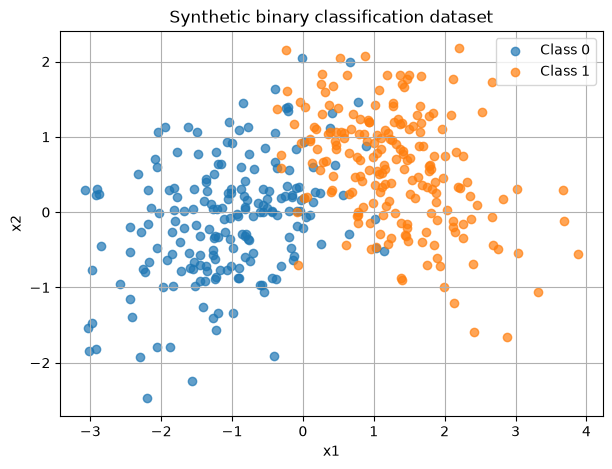

In [3]:
def plot_dataset(X, y):
    plt.figure(figsize=(7, 5))

    plt.scatter(
        X[y[:, 0] == 0, 0],
        X[y[:, 0] == 0, 1],
        label="Class 0",
        alpha=0.7
    )

    plt.scatter(
        X[y[:, 0] == 1, 0],
        X[y[:, 0] == 1, 1],
        label="Class 1",
        alpha=0.7
    )

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title("Synthetic binary classification dataset")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_dataset(X, y)

## 2. Implement logistic regression training loop

Now that you have a dataset, the next step is to implement logistic regression training from scratch.  
You will code the forward pass, the sigmoid activation, the binary cross-entropy loss, and the gradient descent updates all by hand: **without relying on PyTorch’s built-in sigmoid or loss functions**.

**What to do**

1. Initialize parameters
   - Create `w` and `b`, both starting at zeros with `requires_grad=True`.

2. Define custom functions
   - Write your own `sigmoid(z) = 1 / (1 + exp(-z))`.  
   - Write your own binary cross-entropy loss:
     $$
     \ell(y, \hat{y}) = -\frac{1}{n}\sum \big(y \log(\hat{y}) + (1-y)\log(1-\hat{y})\big)
     $$

3. Training loop
   - For a given number of epochs:
     - Compute logits `z = X_tr @ w + b`.  
     - Apply your custom sigmoid to obtain predictions.  
     - Compute your custom BCE loss.  
     - Backpropagate.  
     - Update parameters manually.  
     - Reset gradients.

4. Log losses
   - Keep lists of train and validation losses for each epoch.  

5. Plot
   - Plot training and validation loss curves over epochs.


w: tensor([[3.2528],
        [0.9537]])
b: tensor([-1.0100])


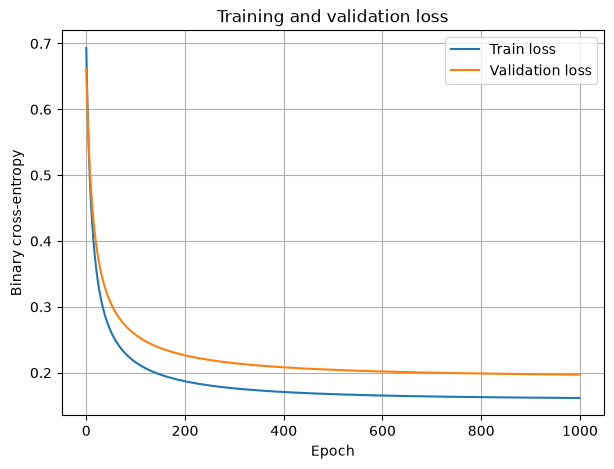

In [4]:
def sigmoid(z):
    return 1 / (1 + torch.exp(-z))


def binary_cross_entropy(y, y_hat):
    return -(y * torch.log(y_hat) +(1 - y) * torch.log(1 - y_hat)).mean()

def train_logistic_regression(X_tr, y_tr, X_val, y_val, lr, epochs):

    train_loss_history = []
    val_loss_history = []

    w = torch.zeros((X_tr.shape[1], 1), requires_grad=True)
    b = torch.zeros(1, requires_grad=True)

    for epoch in range(epochs):

        z = X_tr @ w + b
        y_hat = sigmoid(z)

        train_loss = binary_cross_entropy(y_tr, y_hat)
        train_loss_history.append(train_loss.detach().clone())

        train_loss.backward()

        w.data -= lr * w.grad
        b.data -= lr * b.grad

        w.grad.zero_()
        b.grad.zero_()

        z_val = X_val @ w + b
        y_hat_val = sigmoid(z_val)

        val_loss = binary_cross_entropy(y_val, y_hat_val)
        val_loss_history.append(val_loss.detach().clone())

    return w.detach().clone(), b.detach().clone(), train_loss_history, val_loss_history

lr = 0.1
epochs = 1000

w, b, train_loss, val_loss = train_logistic_regression(
    X_tr, y_tr,
    X_val, y_val,
    lr,
    epochs
)

print("w:", w)
print("b:", b)

def plot_loss_history(train_loss, val_loss):
    plt.figure(figsize=(7, 5))

    plt.plot(train_loss, label="Train loss")
    plt.plot(val_loss, label="Validation loss")

    plt.xlabel("Epoch")
    plt.ylabel("Binary cross-entropy")
    plt.title("Training and validation loss")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_loss_history(train_loss, val_loss)

## 3. Logistic regression with `torch.sigmoid`, SGD optimizer, and built-in losses

Once you’ve implemented everything by hand, it’s time to use PyTorch’s built-in tools.  
This will simplify your code, let you focus on the big picture, and prepare you for real-world usage. You’ll try two ways of using PyTorch’s BCE losses.


**What to do**

1. Setup
   - Initialize `w, b` as before.  
   - Create an SGD optimizer with [`torch.optim.SGD`](https://docs.pytorch.org/docs/stable/generated/torch.optim.SGD.html).  
   - Define number of epochs and learning rate.

2. Variant A — [`BCELoss`](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCELoss.html) (probabilities)
   - Compute logits `z = X @ w + b`.  
   - Apply [`torch.sigmoid`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Sigmoid.html) to obtain probabilities.  
   - Compute loss with `torch.nn.BCELoss`.  
   - Use SGD for parameter updates.

3. Variant B — [`BCEWithLogitsLoss`](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html) (logits)
   - Compute logits `z = X @ w + b`.  
   - Compute loss directly with `torch.nn.BCEWithLogitsLoss`.  

4. Validation
   - At each epoch, compute both train and validation losses.  
   - Keep logs for plotting.

5. Plot
   - Compare loss curves from Variant A and Variant B side by side.  




In [5]:
def train_logistic_regression_bce_a(X_tr, y_tr, X_val, y_val, lr, epochs):

    train_loss_history = []
    val_loss_history = []

    w = torch.zeros((X_tr.shape[1], 1), requires_grad=True)
    b = torch.zeros(1, requires_grad=True)

    optimizer = torch.optim.SGD([w, b], lr=lr)

    loss_fn = torch.nn.BCELoss()

    for epoch in range(epochs):
        z = X_tr @ w + b
        y_hat = torch.sigmoid(z)

        train_loss = loss_fn(y_hat, y_tr)
        train_loss_history.append(train_loss.detach().clone())

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        z_val = X_val @ w + b
        y_hat_val = torch.sigmoid(z_val)

        val_loss = loss_fn(y_hat_val, y_val)
        val_loss_history.append(val_loss.detach().clone())
    

    return w.detach().clone(), b.detach().clone(), train_loss_history, val_loss_history

def train_logistic_bce_b(X_tr, y_tr, X_val, y_val, lr, epochs):

    train_loss_history = []
    val_loss_history = []

    w = torch.zeros((X_tr.shape[1], 1), requires_grad=True)
    b = torch.zeros(1, requires_grad=True)

    optimizer = torch.optim.SGD([w, b], lr=lr)

    loss_fn = torch.nn.BCEWithLogitsLoss()

    for epoch in range(epochs):
        z = X_tr @ w + b

        train_loss = loss_fn(z, y_tr)
        train_loss_history.append(train_loss.detach().clone())

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        z_val = X_val @ w + b

        val_loss = loss_fn(z_val, y_val)
        val_loss_history.append(val_loss.detach().clone())

    return w.detach().clone(), b.detach().clone(), train_loss_history, val_loss_history

Variant A
w: tensor([[3.2528],
        [0.9537]])
b: tensor([-1.0100])

Variant B
w: tensor([[3.2528],
        [0.9537]])
b: tensor([-1.0100])


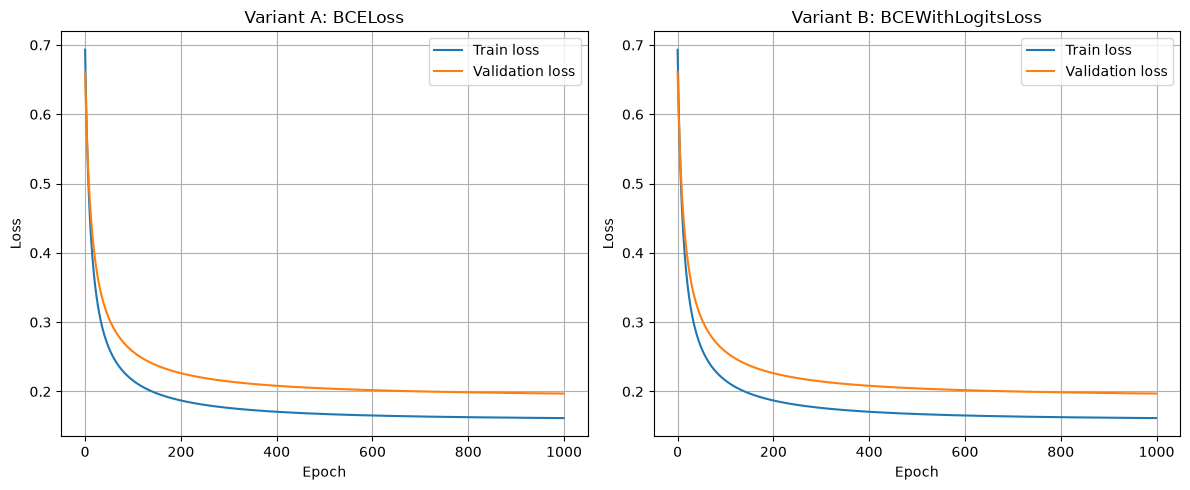

In [6]:
lr = 0.1
epochs = 1000

w_a, b_a, train_loss_a, val_loss_a = train_logistic_regression_bce_a(
    X_tr, y_tr, X_val, y_val, lr, epochs
)

w_b, b_b, train_loss_b, val_loss_b = train_logistic_bce_b(
    X_tr, y_tr, X_val, y_val, lr, epochs
)

print("Variant A")
print("w:", w_a)
print("b:", b_a)

print("\nVariant B")
print("w:", w_b)
print("b:", b_b)

plt.figure(figsize=(12, 5))

# Variant A
plt.subplot(1, 2, 1)

plt.plot(train_loss_a, label="Train loss")
plt.plot(val_loss_a, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Variant A: BCELoss")
plt.legend()
plt.grid(True)


# Variant B
plt.subplot(1, 2, 2)

plt.plot(train_loss_b, label="Train loss")
plt.plot(val_loss_b, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Variant B: BCEWithLogitsLoss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 4. Visualize decision boundary on the training data

Once the model is trained, we want to see how it separates the classes in the input space.  



**What to do**

1. Create a grid  
   - Build a mesh grid covering the range of feature values `(x1, x2)`.

2. Compute predictions  
   - For each point on the grid, compute logits `z = grid @ w + b`.  
   - Apply sigmoid to get probabilities.  
   - Assign class 0 or 1 depending on whether probability $\geq 0.5$.

3. Plot  
   - Show the decision regions as a filled contour plot.  
   - Overlay the training data points with different colors for classes 0 and 1.  
   - Label axes and add a legend.



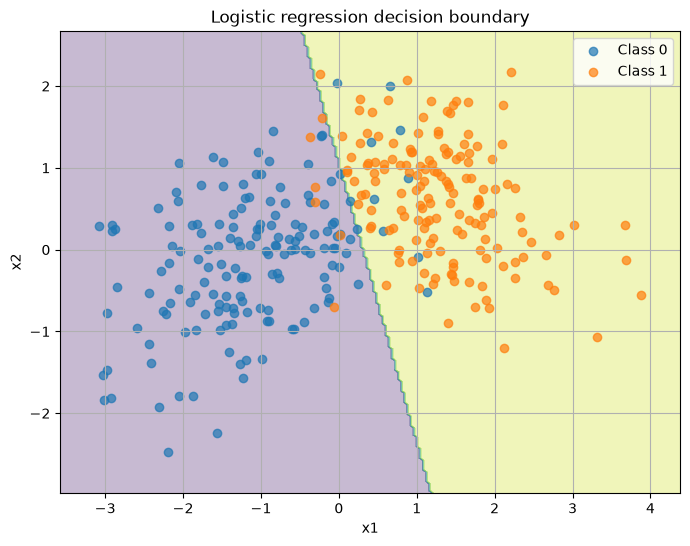

In [7]:
def plot_decision_boundary(X, y, w, b):

    x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    x2_min, x2_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    x1_grid = torch.linspace(x1_min, x1_max, 200)
    x2_grid = torch.linspace(x2_min, x2_max, 200)

    x1_mesh, x2_mesh = torch.meshgrid(
        x1_grid,
        x2_grid,
        indexing="xy"
    )

    grid = torch.stack([x1_mesh.flatten(), x2_mesh.flatten()],dim=1)

    z = grid @ w + b

    probabilities = torch.sigmoid(z)

    predictions = (probabilities >= 0.5).float()
    predictions = predictions.reshape(x1_mesh.shape)

    plt.figure(figsize=(8, 6))

    plt.contourf(x1_mesh.numpy(),x2_mesh.numpy(),predictions.detach().numpy(),alpha=0.3)

    pertenece_clase0 = (y[:, 0] == 0)
    pertenece_clase1 = (y[:, 0] == 1)

    plt.scatter(X[pertenece_clase0, 0],X[pertenece_clase0, 1],label="Class 0",alpha=0.7)

    plt.scatter(X[pertenece_clase1, 0],X[pertenece_clase1, 1],label="Class 1",alpha=0.7)

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title("Logistic regression decision boundary")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_decision_boundary(X_tr,y_tr,w_b,b_b)

## 5. Add polynomial features to logistic regression

Linear decision boundaries can only separate linearly separable data.  
To make logistic regression more expressive, we can expand the feature space with polynomial terms. This allows the model to form curved decision boundaries that adapt to more complex data.  


**What to do**

1. Define a mapping function
   - Use [`sklearn.preprocessing.PolynomialFeatures`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html) to create polynomial features up to a given degree.  
   - Wrap it into a helper function `poly_map(X, degree)` that:  
     - Creates a `PolynomialFeatures` object with the chosen degree (and `include_bias=False`).  
     - Fits it on the input `X` (numpy).  
     - Transforms `X` and converts the result back to a PyTorch tensor.  

2. Apply mapping
   - Transform both training and validation features.  
   - For `degree=1`, you should recover the raw features.  
   - For higher degrees, the function should automatically generate terms like $x_1^2, x_2^2, x_1x_2$, etc.

3. Train
   - Use the same training loop as before with `BCEWithLogitsLoss`.  
   - Replace the input features with the polynomially expanded ones.  

4. Plot
   - Build a mesh grid in the original `(x1, x2)` space.  
   - Pass it through the same `poly_map` before prediction.  
   - Plot the decision boundary in the 2D plane, overlaying the training data.  


In [8]:
from sklearn.preprocessing import PolynomialFeatures
def poly_map(X, degree):
    poly = PolynomialFeatures(degree=degree,include_bias=False)

    X_np = X.numpy()
    X_poly = poly.fit_transform(X_np)

    return torch.tensor(X_poly, dtype=torch.float32)
print(poly_map(X_tr, 1)[0])
print(poly_map(X_tr, 2)[0])

tensor([-3.0311, -1.5326])
tensor([-3.0311, -1.5326,  9.1875,  4.6454,  2.3489])


In [9]:
degree = 6

X_tr_poly = poly_map(X_tr, degree)
X_val_poly = poly_map(X_val, degree)

print("Original:", X_tr.shape)
print("Polynomial:", X_tr_poly.shape)

Original: torch.Size([320, 2])
Polynomial: torch.Size([320, 27])


In [10]:
lr = 0.1
epochs = 1000

w_poly, b_poly, train_loss_poly, val_loss_poly = train_logistic_bce_b(X_tr_poly,y_tr,X_val_poly,y_val,lr,epochs)


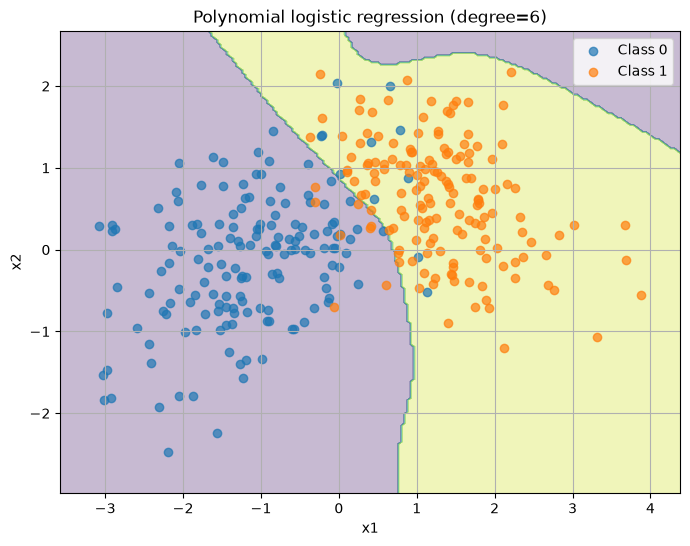

In [11]:
x1_min = X[:, 0].min() - 0.5
x1_max = X[:, 0].max() + 0.5

x2_min = X[:, 1].min() - 0.5
x2_max = X[:, 1].max() + 0.5

x1_grid = torch.linspace(x1_min, x1_max, 200)
x2_grid = torch.linspace(x2_min, x2_max, 200)

x1_mesh, x2_mesh = torch.meshgrid(
    x1_grid,
    x2_grid,
    indexing="xy"
)

grid = torch.stack(
    [
        x1_mesh.flatten(),
        x2_mesh.flatten()
    ],
    dim=1
)

grid_poly = poly_map(grid, degree)

with torch.no_grad():
    z_grid = grid_poly @ w_poly + b_poly
    probabilities = torch.sigmoid(z_grid)
    predictions = (probabilities >= 0.5).float()

predictions = predictions.reshape(x1_mesh.shape)


plt.figure(figsize=(8, 6))

plt.contourf(
    x1_mesh.numpy(),
    x2_mesh.numpy(),
    predictions.numpy(),
    alpha=0.3
)

plt.scatter(
    X_tr[y_tr[:, 0] == 0, 0],
    X_tr[y_tr[:, 0] == 0, 1],
    label="Class 0",
    alpha=0.7
)

plt.scatter(
    X_tr[y_tr[:, 0] == 1, 0],
    X_tr[y_tr[:, 0] == 1, 1],
    label="Class 1",
    alpha=0.7
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title(f"Polynomial logistic regression (degree={degree})")
plt.legend()
plt.grid(True)
plt.show()

## 6. Regularization: compare L1 (manual) and L2 (weight decay)

Adding polynomial features can increase flexibility but also cause overfitting.  
Regularization helps control model complexity by penalizing large weights. 


**What to do**

1. L2 
   - Use `weight_decay` in the optimizer (`torch.optim.SGD`).
   - Train logistic regression with `BCEWithLogitsLoss`.
   - Log train and validation losses.

2. L1 
   - Train a fresh model with optimizer without weight decay.
   - There is no L1 `weight_decay` in PyTorch, so you must add it manually to the loss:
     $
     \text{loss} = \text{BCEWithLogitsLoss}(z,y) + \lambda \|w\|_1
     $
   - Exclude the bias `b` from the penalty.
   - Report validation loss without the L1 term.

3. Compare
   - Plot train and validation losses for both approaches in one figure.  
   - Plot the decision boundaries to see the difference in regularization effects.




In [12]:
def train_logistic_l2(X_tr, y_tr, X_val, y_val, lr, epochs, weight_decay):

    train_loss_history = []
    val_loss_history = []

    w = torch.zeros((X_tr.shape[1], 1), requires_grad=True)
    b = torch.zeros(1, requires_grad=True)

    optimizer = torch.optim.SGD([w, b],lr=lr,weight_decay=weight_decay)

    loss_fn = torch.nn.BCEWithLogitsLoss()

    for epoch in range(epochs):

        z = X_tr @ w + b

        train_loss = loss_fn(z, y_tr)
        train_loss_history.append(train_loss.detach().clone())

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        with torch.no_grad():
            z_val = X_val @ w + b
            val_loss = loss_fn(z_val, y_val)

        val_loss_history.append(val_loss.detach().clone())

    return (w.detach().clone(),b.detach().clone(),train_loss_history,val_loss_history)

def train_logistic_l1(X_tr, y_tr, X_val, y_val, lr, epochs, l1_lambda):

    train_loss_history = []
    val_loss_history = []

    w = torch.zeros((X_tr.shape[1], 1), requires_grad=True)
    b = torch.zeros(1, requires_grad=True)

    optimizer = torch.optim.SGD([w, b],lr=lr)

    loss_fn = torch.nn.BCEWithLogitsLoss()

    for epoch in range(epochs):

        z = X_tr @ w + b

        bce_loss = loss_fn(z, y_tr)

        l1_penalty = l1_lambda * torch.sum(torch.abs(w))

        train_loss = bce_loss + l1_penalty

        train_loss_history.append(train_loss.detach().clone())

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        # Validation loss SIN la penalización L1
        with torch.no_grad():
            z_val = X_val @ w + b
            val_loss = loss_fn(z_val, y_val)

        val_loss_history.append(val_loss.detach().clone())

    return (w.detach().clone(),b.detach().clone(),train_loss_history,val_loss_history)

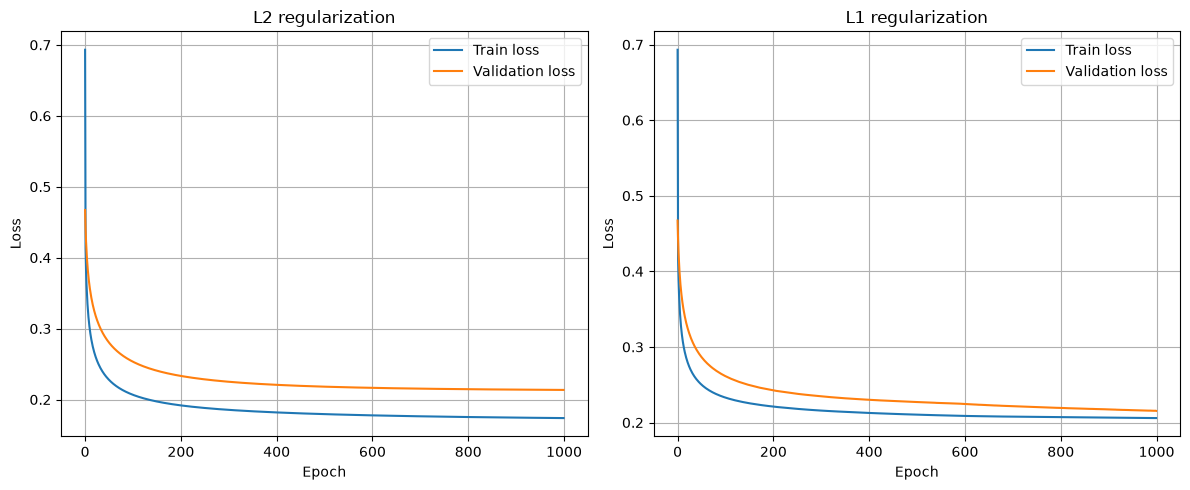

In [16]:
degree = 3

X_tr_poly = poly_map(X_tr, degree)
X_val_poly = poly_map(X_val, degree)

lr = 0.1
epochs = 1000

weight_decay = 0.01
l1_lambda = 0.01

w_l2, b_l2, train_loss_l2, val_loss_l2 = train_logistic_l2(X_tr_poly,y_tr,X_val_poly,y_val,lr,epochs,weight_decay)

w_l1, b_l1, train_loss_l1, val_loss_l1 = train_logistic_l1(X_tr_poly,y_tr,X_val_poly,y_val,lr,epochs,l1_lambda)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(train_loss_l2, label="Train loss")
plt.plot(val_loss_l2, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("L2 regularization")
plt.legend()
plt.grid(True)


plt.subplot(1, 2, 2)

plt.plot(train_loss_l1, label="Train loss")
plt.plot(val_loss_l1, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("L1 regularization")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

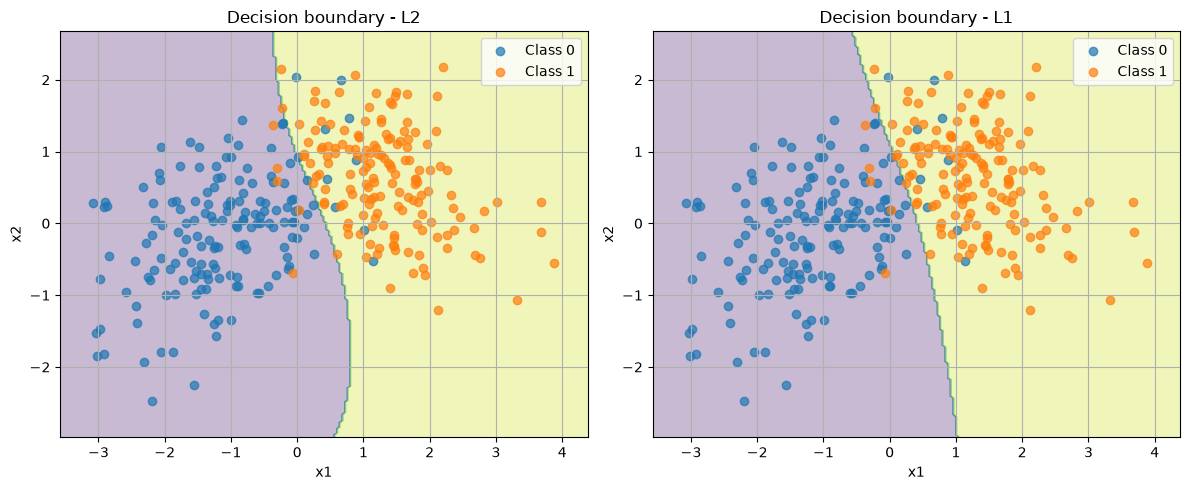

In [17]:
x1_min = X[:, 0].min() - 0.5
x1_max = X[:, 0].max() + 0.5

x2_min = X[:, 1].min() - 0.5
x2_max = X[:, 1].max() + 0.5

x1_grid = torch.linspace(x1_min, x1_max, 200)
x2_grid = torch.linspace(x2_min, x2_max, 200)

x1_mesh, x2_mesh = torch.meshgrid(
    x1_grid,
    x2_grid,
    indexing="xy"
)

grid = torch.stack(
    [x1_mesh.flatten(), x2_mesh.flatten()],
    dim=1
)

grid_poly = poly_map(grid, degree)

def plot_regularized_boundary(
    X,
    y,
    grid_poly,
    x1_mesh,
    x2_mesh,
    w,
    b,
    title
):
    with torch.no_grad():
        z = grid_poly @ w + b
        probabilities = torch.sigmoid(z)
        predictions = (probabilities >= 0.5).float()

    predictions = predictions.reshape(x1_mesh.shape)

    plt.contourf(
        x1_mesh.numpy(),
        x2_mesh.numpy(),
        predictions.numpy(),
        alpha=0.3
    )

    plt.scatter(
        X[y[:, 0] == 0, 0],
        X[y[:, 0] == 0, 1],
        label="Class 0",
        alpha=0.7
    )

    plt.scatter(
        X[y[:, 0] == 1, 0],
        X[y[:, 0] == 1, 1],
        label="Class 1",
        alpha=0.7
    )

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(title)
    plt.legend()
    plt.grid(True)


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plot_regularized_boundary(
    X_tr,
    y_tr,
    grid_poly,
    x1_mesh,
    x2_mesh,
    w_l2,
    b_l2,
    "Decision boundary - L2"
)


plt.subplot(1, 2, 2)

plot_regularized_boundary(
    X_tr,
    y_tr,
    grid_poly,
    x1_mesh,
    x2_mesh,
    w_l1,
    b_l1,
    "Decision boundary - L1"
)

plt.tight_layout()
plt.show()

## 7. Model selection with polynomial degree and L2 weight decay

So far, we trained logistic regression with different features and regularization, but we chose hyperparameters manually.  
A more systematic approach is to try multiple combinations and use the validation set to decide which one works best.  
In this exercise you will implement a grid search over polynomial degree and weight decay values, and then compare models.


**What to do**

1. Define search grid
   - Polynomial degrees: `{1, 2, 3, 4}`.  
   - Weight decay values: `{0, 1e-4, 1e-3, 1e-2, 1e-1}`.

2. Feature mapping
   - If degree = 1, use raw features.  
   - If degree > 1, expand features.  

3. Standardize features
   - Compute mean and std on the training set (after mapping).  
   - Apply the same transformation to both training and validation sets.  

4. Train each model
   - Train logistic regression with `BCEWithLogitsLoss` and SGD, using the given weight decay.  
   - Log train and validation losses.  

5. Evaluate
   - For each combination, compute final validation loss and validation accuracy.  
   - Store results in a table with columns `(degree, lambda, val_loss, val_acc)`.  

6. Select best model
   - Choose the configuration with the lowest validation loss (break ties with higher val accuracy).  

7. Visualize
   - Plot the decision boundary of the best model on the training data, in the original `(x1, x2)` space.  
   - Remember to apply mapping and scaling consistently to the plotting grid.  


In [15]:
degrees = [1, 2, 3, 4]
weight_decays = [0, 1e-4, 1e-3, 1e-2, 1e-1]

lr = 0.1
epochs = 1000

from sklearn.preprocessing import PolynomialFeatures

def poly_map(X, degree):
    if degree == 1:
        return X.clone()

    poly = PolynomialFeatures(
        degree=degree,
        include_bias=False
    )

    X_np = X.numpy()
    X_poly = poly.fit_transform(X_np)

    return torch.tensor(X_poly, dtype=torch.float32)

def standardize_train_val(X_tr, X_val):

    mean = X_tr.mean(dim=0)
    std = X_tr.std(dim=0)

    # Evitar división por cero
    std = torch.where(std == 0, torch.ones_like(std), std)

    X_tr_std = (X_tr - mean) / std
    X_val_std = (X_val - mean) / std

    return X_tr_std, X_val_std, mean, std

def accuracy(y, probabilities):

    predictions = (probabilities >= 0.5).float()

    return (predictions == y).float().mean().item()



## 8. Model selection with 5-fold cross validation

Selecting hyperparameters on a single validation split can bias results.  
A more robust approach is k-fold cross validation, where the dataset is split into several folds and each fold is used once as validation while the rest serve as training.  
In this exercise you will perform 5-fold cross validation to choose the best polynomial degree and weight decay.


**What to do**

1. Define search grid
   - Polynomial degrees: `{1, 2, 3, 4}`.  
   - Weight decay values: `{0, 1e-4, 1e-3, 1e-2, 1e-1}`.  

2. Split into folds
   - Shuffle the dataset once.  
   - Partition indices into 5 folds of roughly equal size.  

3. Cross validation loop
   - For each (degree, λ) pair and each fold:
     - Use 4 folds as training, 1 fold as validation.  
     - Apply the adequate polynomial transformation and standarization.  
     - Train logistic regression with SGD and `BCEWithLogitsLoss` + weight decay.  
     - Record validation loss and validation accuracy.  

4. Aggregate results
   - Compute the mean validation loss and accuracy across the 5 folds for each hyperparameter pair.  

5. Select best configuration
   - Pick the (degree, λ) with the lowest mean validation loss (tie-break with accuracy).  

6. Retrain final model
   - Train logistic regression once more on the entire dataset using the best hyperparameters.  

7. Visualize
   - Plot the decision boundary of the final model in the original `(x1, x2)` space.  


